<a href="https://colab.research.google.com/github/solitude-ui/CIFAR-100-Image-Classification/blob/main/Assesment_Computer_Vision_Case_Study.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#AIML **Computer Vision** Case Study



> Training and Evaluating CNN Models on CIFAR-100



#Load Libraries

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers,Sequential,regularizers
#dataset
from tensorflow.keras.datasets import cifar100
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import EarlyStopping,ModelCheckpoint


import matplotlib.pyplot as plt
import numpy as np
#for plot model
!pip install pydot
!apt-get install -y graphviz
from tensorflow.keras.utils import plot_model

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
graphviz is already the newest version (2.42.2-9ubuntu0.1).
0 upgraded, 0 newly installed, 0 to remove and 33 not upgraded.


#Load Data - **CIFAR-100**

In [ ]:
(X_train,y_train),(X_test,y_test)=cifar100.load_data()

169001437/169001437 ━━━━━━━━━━━━━━━━━━━━ 1630s 10us/step


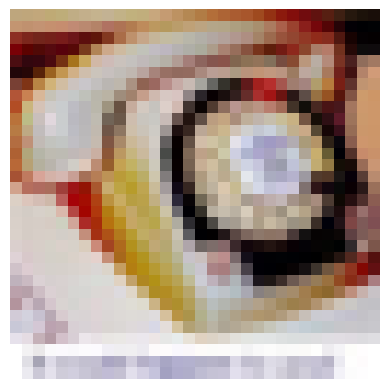

In [ ]:
#Display image
image=X_train[5]
plt.imshow(image,cmap='gray')
plt.axis("off")#Hide axis ticks
plt.show()

In [ ]:
#shape
print(X_train.shape)

(50000, 32, 32, 3)


#Preprocess the Data

In [ ]:
# #To change the shape to match rgb values into last position---CIFAR-100 already contains RGB with 3 channels
# X_train=tf.expand_dims(X_train,-1)
# X_test=tf.expand_dims(X_test,-1)

In [ ]:
#Normalize pixel values -[0,255] to [0.0,1.0]
X_train=tf.cast(X_train,tf.float32)/255.0
X_test=tf.cast(X_test,tf.float32)/255.0

In [ ]:
#One=Hot encoding the target

y_train=to_categorical(y_train,100)
y_test=to_categorical(y_test,100)

print("Training labels shape:", y_train.shape)
print("Testing labels shape:", y_test.shape)

Training labels shape: (50000, 100)
Testing labels shape: (10000, 100)


#Define custom CNN model

In [ ]:
# Define Custom CNN Model
custom_cnn_model = Sequential([

    # Input: 32 x 32 RGB image

    # Block 1
    layers.Conv2D(
        32, (3, 3),
        padding="same",
        kernel_initializer="he_normal",
        kernel_regularizer=regularizers.l2(0.001),
        input_shape=(32, 32, 3)
    ),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.Conv2D(
        32, (3, 3),
        padding="same",
        activation="relu",
        kernel_initializer="he_normal"
    ),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    # Block 2
    layers.Conv2D(
        64, (3, 3),
        padding="same",
        kernel_initializer="he_normal"
    ),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.Conv2D(
        64, (3, 3),
        padding="same",
        activation="relu",
        kernel_initializer="he_normal"
    ),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.30),

    # Block 3
    layers.Conv2D(
        128, (3, 3),
        padding="same",
        kernel_initializer="he_normal"
    ),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.35),

    # Classifier
    layers.GlobalAveragePooling2D(),
    layers.Dense(
        256,
        activation="relu",
        kernel_initializer="he_normal",
        kernel_regularizer=regularizers.l2(0.001)
    ),
    layers.Dropout(0.5),

    # Output: 100 CIFAR-100 classes
    layers.Dense(100, activation="softmax")
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


##compile the model

In [ ]:
custom_cnn_model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

# Display model architecture
custom_cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 100)            │        25,700 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 199,044 (777.52 KB)

 Trainable params: 198,596 (775.77 KB)

 Non-trainable params: 448 (1.75 KB)

##Configure callbacks

In [ ]:
# Stop training when validation loss stops improving
early_stopping_custom = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

# Save the best model based on validation loss
checkpoint_custom = ModelCheckpoint(
    "best_custom_cnn.keras",
    monitor="val_loss",
    save_best_only=True,
    mode="min"
)

##Train the custom CNN

In [ ]:
history_custom = custom_cnn_model.fit(
    X_train,
    y_train,
    batch_size=128,
    epochs=100,
    validation_split=0.1,
    callbacks=[
        early_stopping_custom,
        checkpoint_custom
    ]
)

Epoch 1/100
352/352 ━━━━━━━━━━━━━━━━━━━━ 37s 59ms/step - accuracy: 0.0571 - loss: 4.6640 - val_accuracy: 0.0460 - val_loss: 4.7164
Epoch 2/100
352/352 ━━━━━━━━━━━━━━━━━━━━ 12s 15ms/step - accuracy: 0.1120 - loss: 4.0270 - val_accuracy: 0.1462 - val_loss: 3.7910
Epoch 3/100
352/352 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - accuracy: 0.1589 - loss: 3.6447 - val_accuracy: 0.1980 - val_loss: 3.4447
Epoch 4/100
352/352 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - accuracy: 0.1990 - loss: 3.3774 - val_accuracy: 0.1792 - val_loss: 3.4952
Epoch 5/100
352/352 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - accuracy: 0.2293 - loss: 3.1925 - val_accuracy: 0.1808 - val_loss: 3.4150
Epoch 6/100
352/352 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - accuracy: 0.2528 - loss: 3.0640 - val_accuracy: 0.2990 - val_loss: 2.8625
Epoch 7/100
352/352 ━━━━━━━━━━━━━━━━━━━━ 10s 15ms/step - accuracy: 0.2680 - loss: 2.9596 - val_accuracy: 0.3026 - val_loss: 2.8366
Epoch 8/100
352/352 ━━━━━━━━━━━━━━━━━━━━ 10s 15ms/step - accuracy: 0.2867 - loss: 2.870

#Define Vgg-16 Model

In [ ]:
# Define VGG-16 Model
vgg_16_model = Sequential([

    # Block 1: 64 filters
    layers.Conv2D(64, (3, 3), activation="relu",
                  padding="same", input_shape=(224, 224, 3)),
    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Block 2: 128 filters
    layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Block 3: 256 filters
    layers.Conv2D(256, (3, 3), activation="relu", padding="same"),
    layers.Conv2D(256, (3, 3), activation="relu", padding="same"),
    layers.Conv2D(256, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Block 4: 512 filters
    layers.Conv2D(512, (3, 3), activation="relu", padding="same"),
    layers.Conv2D(512, (3, 3), activation="relu", padding="same"),
    layers.Conv2D(512, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Block 5: 512 filters
    layers.Conv2D(512, (3, 3), activation="relu", padding="same"),
    layers.Conv2D(512, (3, 3), activation="relu", padding="same"),
    layers.Conv2D(512, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Fully connected layers
    layers.Flatten(),
    layers.Dense(4096, activation="relu"),
    layers.Dense(4096, activation="relu"),

    # CIFAR-100 output layer
    layers.Dense(100, activation="softmax")
])

In [ ]:
X_train_vgg = tf.image.resize(X_train, (224, 224))
X_test_vgg = tf.image.resize(X_test, (224, 224))

##Compile the model

In [ ]:
#compile the model
vgg_16_model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
#view the model
vgg_16_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_5 (Conv2D)               │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 7, 7, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 4096)           │   102,764,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4096)           │    16,781,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 100)            │       409,700 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 134,670,244 (513.73 MB)

 Trainable params: 134,670,244 (513.73 MB)

 Non-trainable params: 0 (0.00 B)

##Train the model

In [ ]:
#define early stopping
early_stopping = EarlyStopping(
    monitor='val_loss',

    patience=3,
    restore_best_weights=True
)

In [ ]:
vgg_16_model.fit(X_train,y_train,batch_size=128,epochs=100,validation_split=0.1,callbacks=[early_stopping])

Epoch 1/100


ValueError: Exception encountered when calling Sequential.call().

[1mInput 0 with name 'None' of layer 'dense_2' is incompatible with the layer: expected axis -1 of input shape to have value 25088, but received input with shape (None, 512)[0m

Arguments received by Sequential.call():
  • inputs=tf.Tensor(shape=(None, 32, 32, 3, 1), dtype=float32)
  • training=True
  • mask=None
  • kwargs=<class 'inspect._empty'>

##Evaluate the model

In [ ]:
test_loss,test_acc=vgg_16_model.evaluate (X_test,y_test)
print("Test Accuraccy: ",test_acc)

##Analyse model Performance

In [ ]:
#select raw 3D tensor sample:Shape(28,28,1)
sample_tensor=X_test[100]
plt.imshow(sample_tensor,cmap="gray")
plt.show()

In [ ]:
#Add batch dimension to raw sample for model input:
input_tensor=np.expand_dims(sample_tensor,axis=0)

#predict using explicit CNN model
predictions=vgg_16_model.predict(input_tensor)

#Get predicted class
predicted_class=np.argmax(predictions[0])

print(f"\n predicted Digit: {predicted_class}")
print(f"Class probabilities: {predictions[0].round(3)}")

##Save the model history

In [ ]:
history_vgg16 = vgg_16_model.fit(
    X_train,
    y_train,
    batch_size=128,
    epochs=100,
    validation_split=0.1,
    callbacks=[early_stopping]
)

#Evaluate both Models

##Test Accuracy comparison

In [ ]:
# Evaluate VGG-16
vgg_test_loss, vgg_test_acc = vgg_16_model.evaluate(
    X_test, y_test, verbose=0
)

# Evaluate Custom CNN
custom_test_loss, custom_test_acc = custom_cnn_model.evaluate(
    X_test, y_test, verbose=0
)

# Display comparison table
import pandas as pd

results = pd.DataFrame({
    "Model": ["VGG-16", "Custom CNN"],
    "Test Loss": [vgg_test_loss, custom_test_loss],
    "Test Accuracy (%)": [
        vgg_test_acc * 100,
        custom_test_acc * 100
    ]
})

print(results.round(2))

##training and validation curves

In [ ]:


fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy curves
axes[0].plot(
    history_vgg16.history["accuracy"],
    label="VGG-16 Training"
)
axes[0].plot(
    history_vgg16.history["val_accuracy"],
    label="VGG-16 Validation"
)
axes[0].plot(
    history_custom.history["accuracy"],
    label="Custom CNN Training"
)
axes[0].plot(
    history_custom.history["val_accuracy"],
    label="Custom CNN Validation"
)

axes[0].set_title("Training and Validation Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

# Loss curves
axes[1].plot(
    history_vgg16.history["loss"],
    label="VGG-16 Training"
)
axes[1].plot(
    history_vgg16.history["val_loss"],
    label="VGG-16 Validation"
)
axes[1].plot(
    history_custom.history["loss"],
    label="Custom CNN Training"
)
axes[1].plot(
    history_custom.history["val_loss"],
    label="Custom CNN Validation"
)

axes[1].set_title("Training and Validation Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()

plt.tight_layout()
plt.show()

#Result and Conclusion